# Brownian motion、GBM 与期权定价

主线：随机冲击 → 随机路径 → 资产价格路径 → 金融定价。

[返回理论正文](../../lectures/monte-carlo.qmd#sec-mc-process) · [下载 Notebook (ZIP)](../../resources/monte-carlo/downloads/04-brownian-gbm-option.zip)

页面展示交接包已保存的执行结果；渲染不执行代码。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import log, sqrt, exp, erf
SEED = 20261001

## 离散随机游走

\[
X_{t+1}=X_t+\epsilon_{t+1},\qquad \epsilon_t\sim N(0,\sigma^2).
\]

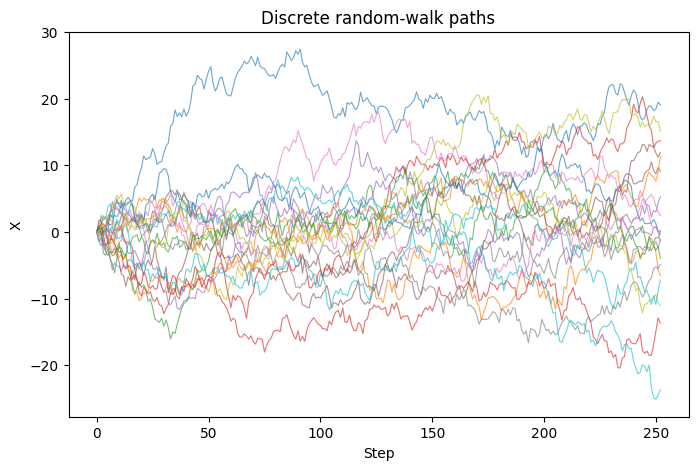

In [2]:
rng = np.random.default_rng(SEED)
T_steps = 252
n_paths = 20
eps = rng.normal(0, 1, size=(n_paths, T_steps))
paths = np.c_[np.zeros(n_paths), np.cumsum(eps, axis=1)]
fig, ax = plt.subplots(figsize=(8,5))
for row in paths:
    ax.plot(row, linewidth=0.8, alpha=0.65)
ax.set_xlabel("Step"); ax.set_ylabel("X"); ax.set_title("Discrete random-walk paths")
plt.show()

## Brownian motion

\[
W_{t+\Delta t}-W_t\sim N(0,\Delta t).
\]

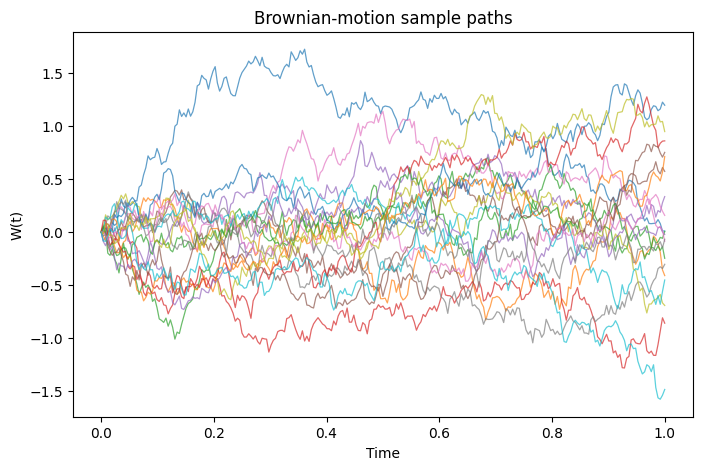

In [3]:
T = 1.0
N = 252
dt = T / N
rng = np.random.default_rng(SEED)
dW = rng.normal(0, np.sqrt(dt), size=(20, N))
W = np.c_[np.zeros(20), np.cumsum(dW, axis=1)]
t = np.linspace(0, T, N + 1)
fig, ax = plt.subplots(figsize=(8,5))
for row in W:
    ax.plot(t, row, linewidth=0.9, alpha=0.7)
ax.set_xlabel("Time"); ax.set_ylabel("W(t)"); ax.set_title("Brownian-motion sample paths")
plt.show()

In [4]:
rng = np.random.default_rng(SEED)
WT = rng.normal(0, np.sqrt(T), size=100000)
pd.Series({
    "mean_WT": WT.mean(),
    "sd_WT": WT.std(ddof=1),
    "theoretical_mean": 0.0,
    "theoretical_sd": np.sqrt(T),
})

mean_WT            -0.002359
sd_WT               1.000235
theoretical_mean    0.000000
theoretical_sd      1.000000
dtype: float64

## Geometric Brownian Motion

\[
dS_t=\mu S_tdt+\sigma S_tdW_t,
\]

\[
S_t=S_0\exp\left[\left(\mu-\frac12\sigma^2\right)t+\sigma W_t\right].
\]

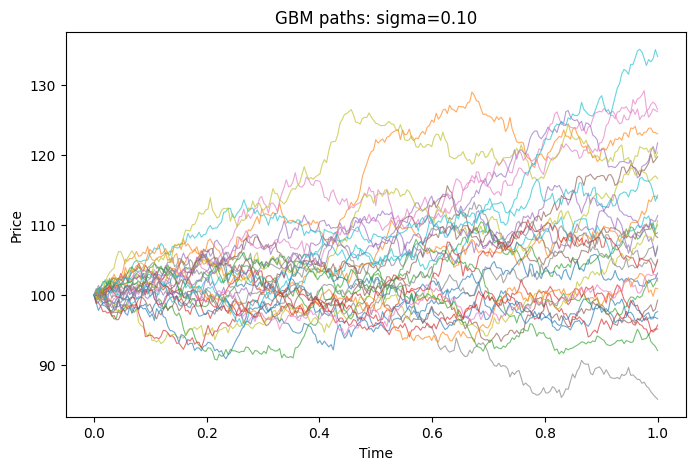

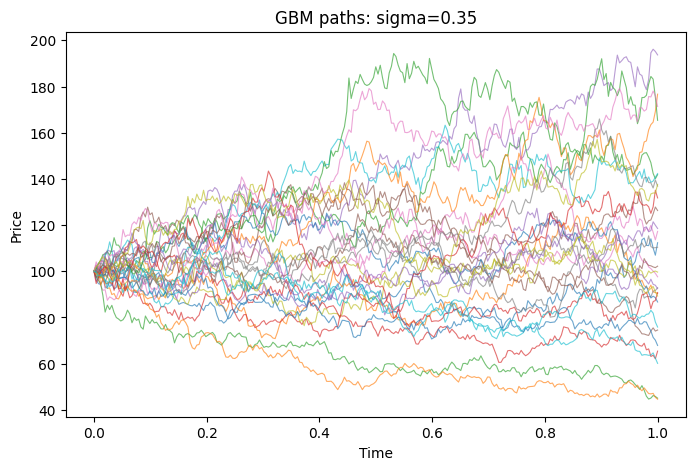

In [5]:
def gbm_paths(S0=100, mu=0.08, sigma=0.2, T=1.0, N=252, n_paths=50, seed=SEED):
    rng = np.random.default_rng(seed)
    dt = T / N
    dW = rng.normal(0, np.sqrt(dt), size=(n_paths, N))
    W = np.c_[np.zeros(n_paths), np.cumsum(dW, axis=1)]
    t = np.linspace(0, T, N + 1)
    S = S0 * np.exp((mu - 0.5*sigma**2)*t[None,:] + sigma*W)
    return t, S

for sigma in [0.10, 0.35]:
    t, S = gbm_paths(sigma=sigma, n_paths=30, seed=SEED + int(sigma*1000))
    fig, ax = plt.subplots(figsize=(8,5))
    for row in S:
        ax.plot(t, row, linewidth=0.8, alpha=0.65)
    ax.set_xlabel("Time"); ax.set_ylabel("Price")
    ax.set_title(f"GBM paths: sigma={sigma:.2f}")
    plt.show()

## 终值风险与路径风险不同

In [6]:
S0=100; mu=0.08; sigma=0.30; T=1; N=252; n_paths=5000; barrier=75
t, S = gbm_paths(S0=S0, mu=mu, sigma=sigma, T=T, N=N, n_paths=n_paths, seed=SEED)
terminal = S[:, -1]
hit_barrier = (S.min(axis=1) < barrier)
pd.Series({
    "P(S_T > S0)": np.mean(terminal > S0),
    "P(path ever falls below barrier)": np.mean(hit_barrier),
    "P(S_T > S0 AND path hit barrier)": np.mean((terminal > S0) & hit_barrier),
})

P(S_T > S0)                         0.5498
P(path ever falls below barrier)    0.2804
P(S_T > S0 AND path hit barrier)    0.0266
dtype: float64

## 风险中性 Monte Carlo 期权定价

\[
C_0=e^{-rT}E^Q[(S_T-K)^+].
\]

In [7]:
def normal_cdf(x):
    return 0.5 * (1 + erf(x / sqrt(2)))

def bs_call_price(S0, K, r, sigma, T):
    d1 = (log(S0/K)+(r+0.5*sigma**2)*T)/(sigma*sqrt(T))
    d2 = d1 - sigma*sqrt(T)
    return S0*normal_cdf(d1) - K*exp(-r*T)*normal_cdf(d2)

def mc_call_price(S0, K, r, sigma, T, B, seed=SEED):
    rng = np.random.default_rng(seed)
    Z = rng.normal(size=B)
    ST = S0*np.exp((r-0.5*sigma**2)*T + sigma*np.sqrt(T)*Z)
    payoff = np.maximum(ST-K, 0)
    return np.exp(-r*T)*payoff.mean()

S0=100; K=100; r=0.05; sigma=0.20; T=1.0
bs_price = bs_call_price(S0,K,r,sigma,T)
mc_price = mc_call_price(S0,K,r,sigma,T,B=100000)
pd.Series({
    "Black-Scholes closed-form": bs_price,
    "Monte Carlo estimate": mc_price,
    "MC minus BS": mc_price - bs_price,
})

Black-Scholes closed-form    10.450584
Monte Carlo estimate         10.416516
MC minus BS                  -0.034067
dtype: float64

In [8]:
B_grid = [100,500,1000,5000,10000,50000,100000]
rows=[]
for B in B_grid:
    p = mc_call_price(S0,K,r,sigma,T,B=B,seed=SEED)
    rows.append({"B":B,"MC_price":p,"error_vs_BS":p-bs_price})
conv = pd.DataFrame(rows)
conv

,B,MC_price,error_vs_BS
0,100,13.639128,3.188544
1,500,10.855077,0.404494
2,1000,10.565390,0.114806
3,5000,10.510013,0.059430
4,10000,10.516213,0.065630
5,50000,10.449630,-0.000953
6,100000,10.416516,-0.034067


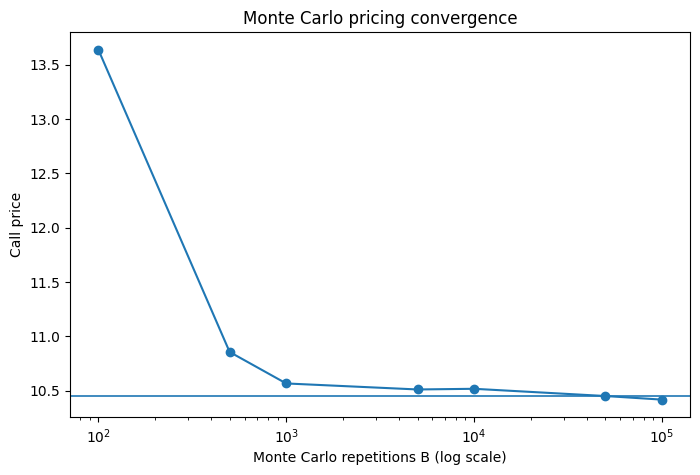

In [9]:
fig, ax = plt.subplots(figsize=(8,5))
ax.plot(conv["B"], conv["MC_price"], marker="o")
ax.axhline(bs_price, linewidth=1.2)
ax.set_xscale("log")
ax.set_xlabel("Monte Carlo repetitions B (log scale)")
ax.set_ylabel("Call price")
ax.set_title("Monte Carlo pricing convergence")
plt.show()

## 教学结论

1. 随机冲击会沿时间累积成随机路径；
2. GBM 把 Brownian motion 转化为始终为正的资产价格过程；
3. 终值分布与完整路径包含不同信息；
4. Monte Carlo 可以把风险中性期望直接转成数值定价，但自身也有近似误差。

Ito 引理、Black–Scholes PDE 和完整随机微积分推导不进入本 Notebook 主线。

[返回理论正文](../../lectures/monte-carlo.qmd#sec-mc-process) · [下载 Notebook (ZIP)](../../resources/monte-carlo/downloads/04-brownian-gbm-option.zip)

页面展示交接包已保存的执行结果；渲染不执行代码。